# LAB 4
En este lab repasaremos los conceptos vistos en la clase 5: Capital Market Line (CML), Maximum Sharpe Ratio Portfolio (MSR) y Global Minimum Variance Portfolio (GMV).

## Bibliotecas a importar

* yfinance: la usaremos para descargar información
* numpy: la usaremos para realizar diversas operaciones matemáticas
* pandas: la usaremos para realizar cálculos con vectores
* matplotlib: la usaremos para personalizar algunas gráficas
* analisis_portafolios: nuestra biblioteca del curso que tendrá funciones para los procedimientos

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analisis_portafolios as ap

## Descargamos la información a analizar
Usamos las mismas empresas del Lab 3 para poder comparar resultados.

In [2]:
tickers = ["AAPL", "MSFT", "JPM", "KO", "XOM"] # tickers de las acciones a analizar
fecha_inicio = "2025-01-01" # fecha de inicio para descargar
fecha_fin = "2025-12-31" # fecha final para descargar

In [3]:
datos = yf.download(tickers, start=fecha_inicio, end=fecha_fin)

curl_cffi not available; falling back to requests without browser TLS impersonation. Yahoo Finance may rate-limit or block this client. Install curl_cffi (>=0.15) for the supported configuration.
[*********************100%***********************]  5 of 5 completed


In [4]:
# extraemos los precios de cierre de todas las empresas
precios_cierre = datos["Close"]
precios_cierre.head()

Ticker,AAPL,JPM,KO,MSFT,XOM
Date,,,,,
2025-01-02,242.093140,230.583771,58.923298,412.895355,101.475349
2025-01-03,241.606659,233.735077,58.837543,417.600555,101.995438
2025-01-06,243.234833,232.595535,57.941879,422.039459,101.881966
2025-01-07,240.464935,234.835999,57.970463,416.633850,102.837059
2025-01-08,240.951401,234.797409,58.799431,418.794189,101.116013


In [5]:
rend_simple = precios_cierre.pct_change().dropna()

In [6]:
# rendimiento esperado y volatilidad anualizados de cada activo
rend_esperado = ap.rendimiento_anualizado(rend_simple)
vol_activos = ap.volatilidad_anualizada(rend_simple)

# matriz de covarianzas anualizada
cov = ap.matriz_covarianza_anualizada(rend_simple)

pd.DataFrame({"Rendimiento": rend_esperado, "Volatilidad": vol_activos}).round(4)

,Rendimiento,Volatilidad
Ticker,,
AAPL,0.1271,0.3253
JPM,0.3832,0.2495
KO,0.1694,0.1757
MSFT,0.1762,0.2433
XOM,0.1718,0.2350


## Tasa libre de riesgo y Sharpe Ratio

La tasa libre de riesgo $r_f$ se incorpora al modelo como un activo con rendimiento conocido y **volatilidad 0**.

Recordemos que el Sharpe Ratio mide el rendimiento **en exceso** de la tasa libre de riesgo por cada unidad de volatilidad:

$$ SR_p = \frac{r_p - r_f}{\sigma_p} $$

In [7]:
# tasa libre de riesgo anualizada (ajústala a la tasa vigente, por ejemplo CETES)
rf = 0.07

In [8]:
# Sharpe de cada activo por separado
sharpe_activos = (rend_esperado - rf) / vol_activos
sharpe_activos.round(4)

Ticker
AAPL    0.1755
JPM     1.2556
KO      0.5659
MSFT    0.4365
XOM     0.4333
dtype: float64

**NOTA:** Es lo mismo que obtenemos con la función `sharpe_ratio` del Lab 1.

In [9]:
ap.sharpe_ratio(rend_simple, rf).round(4)

Ticker
AAPL    0.1755
JPM     1.2556
KO      0.5659
MSFT    0.4365
XOM     0.4333
dtype: float64

## Frontera eficiente con N activos

Para cada rendimiento objetivo $r^*$ buscamos el portafolio de **menor volatilidad**:

$$ \min_{w} \; \sqrt{w^\top \Sigma \, w} $$

sujeto a:

$$ w^\top r = r^* \qquad \sum_i w_i = 1 \qquad 0 \le w_i \le 1 $$

donde $r$ es el vector de rendimientos esperados y $\Sigma$ la matriz de covarianzas.

In [12]:
frontera = ap.frontera_eficiente(rend_esperado, cov)
frontera.head()

Ticker,Rendimiento,Volatilidad,AAPL,JPM,KO,MSFT,XOM
0,0.180342,0.125177,0.000000e+00,0.040779,0.525723,0.265119,0.168379
1,0.184482,0.125247,1.258352e-17,0.060457,0.519438,0.257219,0.162886
2,0.188622,0.125452,1.357963e-17,0.080184,0.514917,0.247973,0.156926
3,0.192762,0.125789,1.179747e-17,0.099910,0.510382,0.238704,0.151004
4,0.196903,0.126258,3.561604e-17,0.119637,0.505848,0.229432,0.145083


## Maximum Sharpe Ratio Portfolio (MSR)

El MSR es el portafolio de la frontera eficiente con el mayor Sharpe Ratio:

$$ \max_{w} \; SR_p = \frac{r_p - r_f}{\sigma_p} = \frac{\sum_{i=1}^{N} w_i r_i - r_f}{\sqrt{\sum_{i,j=1}^{N} w_i w_j \sigma_{ij}}} $$

sujeto a:

$$ \sum_i w_i = 1 \qquad 0 \le w_i \le 1 $$

Veremos las dos alternativas de la clase para encontrarlo.

### Alternativa 1: optimización
Buscamos directamente los pesos que maximizan el Sharpe Ratio con el optimizador de `scipy`.

In [13]:
pesos_msr = ap.portafolio_max_sharpe(rend_esperado, cov, rf)
pd.Series(pesos_msr, index=rend_esperado.index).round(4)

Ticker
AAPL    0.0000
JPM     0.6497
KO      0.3503
MSFT    0.0000
XOM     0.0000
dtype: float64

In [14]:
rend_msr = ap.rendimiento_portafolio(pesos_msr, rend_esperado)
vol_msr = ap.volatilidad_portafolio(pesos_msr, cov)
sharpe_msr = (rend_msr - rf) / vol_msr

print(f"Rendimiento MSR: {rend_msr:.2%}")
print(f"Volatilidad MSR: {vol_msr:.2%}")
print(f"Sharpe MSR: {sharpe_msr:.4f}")

Rendimiento MSR: 30.83%
Volatilidad MSR: 17.82%
Sharpe MSR: 1.3373


**NOTA:** Si ningún activo tiene un rendimiento esperado mayor a la tasa libre de riesgo, el MSR no tiene sentido económico: convendría invertir todo en el activo libre de riesgo.

### Alternativa 2: revisar los portafolios de la frontera
Calculamos el Sharpe de cada portafolio de la frontera y nos quedamos con el mayor.

In [15]:
frontera["Sharpe"] = (frontera["Rendimiento"] - rf) / frontera["Volatilidad"]
msr_frontera = frontera.loc[frontera["Sharpe"].idxmax()]
msr_frontera.round(4)

Ticker
Rendimiento    0.3087
Volatilidad    0.1785
AAPL           0.0000
JPM            0.6514
KO             0.3486
MSFT           0.0000
XOM            0.0000
Sharpe         1.3373
Name: 31, dtype: float64

In [16]:
# comparamos ambas alternativas
pd.DataFrame({
    "Optimización": [rend_msr, vol_msr, sharpe_msr],
    "Búsqueda en la frontera": [msr_frontera["Rendimiento"], msr_frontera["Volatilidad"], msr_frontera["Sharpe"]],
}, index=["Rendimiento", "Volatilidad", "Sharpe"]).round(4)

,Optimización,Búsqueda en la frontera
Rendimiento,0.3083,0.3087
Volatilidad,0.1782,0.1785
Sharpe,1.3373,1.3373


La búsqueda sólo revisa los puntos que calculamos de la frontera, por eso el resultado es aproximado. Entre más puntos (`n_puntos`) usemos, más se acerca al resultado de la optimización.

## Capital Market Line (CML)

La CML es la recta que pasa por la tasa libre de riesgo $(0, r_f)$ y por el MSR $(\sigma_{MSR}, r_{MSR})$:

$$ r = r_f + \frac{r_{MSR} - r_f}{\sigma_{MSR}} \, \sigma $$

Su pendiente es el Sharpe Ratio del MSR.

In [17]:
pendiente_cml = (rend_msr - rf) / vol_msr
print(f"Ecuación de la CML: r = {rf:.4f} + {pendiente_cml:.4f} * sigma")

Ecuación de la CML: r = 0.0700 + 1.3373 * sigma


In [18]:
# rendimiento sobre la CML para algunas volatilidades
volatilidades = np.array([0.0, 0.05, 0.10, vol_msr, 0.25])
pd.Series(ap.rendimiento_cml(volatilidades, rend_msr, vol_msr, rf), index=volatilidades.round(4)).round(4)

0.0000    0.0700
0.0500    0.1369
0.1000    0.2037
0.1782    0.3083
0.2500    0.4043
dtype: float64

### Portafolios sobre la CML
Cada punto de la CML combina el activo libre de riesgo con el MSR. Si invertimos una proporción $a$ en el MSR y $1-a$ en el activo libre de riesgo:

$$ r_p = (1-a)\, r_f + a\, r_{MSR} \qquad \sigma_p = a\, \sigma_{MSR} $$

* $a = 0$: todo en el activo libre de riesgo (riesgo 0).
* $a = 1$: todo en el MSR.
* $a > 1$: pedimos prestado a la tasa libre de riesgo para invertir más del 100% en el MSR (**apalancamiento**). La CML continúa después del MSR.

In [19]:
cml = ap.portafolios_cml(rend_msr, vol_msr, rf)
cml.round(4)

,Peso MSR,Peso Libre de Riesgo,Rendimiento,Volatilidad,Sharpe
0,0.0,1.0,0.0700,0.0000,NaN
1,0.1,0.9,0.0938,0.0178,1.3373
2,0.2,0.8,0.1177,0.0356,1.3373
3,0.3,0.7,0.1415,0.0535,1.3373
4,0.4,0.6,0.1653,0.0713,1.3373
5,0.5,0.5,0.1892,0.0891,1.3373
6,0.6,0.4,0.2130,0.1069,1.3373
7,0.7,0.3,0.2368,0.1247,1.3373
8,0.8,0.2,0.2607,0.1426,1.3373
9,0.9,0.1,0.2845,0.1604,1.3373


**OBSERVACIÓN:** Todos los portafolios con riesgo de la CML tienen el mismo Sharpe Ratio, pues corresponde a la pendiente de la recta. En el punto $a = 0$ el Sharpe no está definido (0/0).

In [20]:
cml["Sharpe"].describe().round(6)

count    15.000000
mean      1.337332
std       0.000000
min       1.337332
25%       1.337332
50%       1.337332
75%       1.337332
max       1.337332
Name: Sharpe, dtype: float64

### ¿Cómo elegimos un portafolio de la CML?
Según nuestro apetito al riesgo. Por ejemplo, si sólo toleramos una **volatilidad objetivo**:

$$ a = \frac{\sigma^*}{\sigma_{MSR}} $$

In [21]:
vol_objetivo = 0.10
a_vol = vol_objetivo / vol_msr

print(f"Proporción en el MSR: {a_vol:.2%}")
print(f"Proporción en el activo libre de riesgo: {1 - a_vol:.2%}")
print(f"Rendimiento esperado: {ap.rendimiento_cml(vol_objetivo, rend_msr, vol_msr, rf):.2%}")

Proporción en el MSR: 56.11%
Proporción en el activo libre de riesgo: 43.89%
Rendimiento esperado: 20.37%


O si buscamos un **rendimiento objetivo**:

$$ a = \frac{r^* - r_f}{r_{MSR} - r_f} $$

In [22]:
rend_objetivo = 0.25
a_rend = (rend_objetivo - rf) / (rend_msr - rf)

print(f"Proporción en el MSR: {a_rend:.2%}")
print(f"Proporción en el activo libre de riesgo: {1 - a_rend:.2%}")
print(f"Volatilidad: {a_rend * vol_msr:.2%}")

Proporción en el MSR: 75.53%
Proporción en el activo libre de riesgo: 24.47%
Volatilidad: 13.46%


La inversión en cada acción es la proporción $a$ multiplicada por los pesos del MSR. Una proporción negativa en el activo libre de riesgo significa que estamos pidiendo prestado.

In [23]:
pd.DataFrame({
    f"Volatilidad {vol_objetivo:.0%}": np.append(a_vol * pesos_msr, 1 - a_vol),
    f"Rendimiento {rend_objetivo:.0%}": np.append(a_rend * pesos_msr, 1 - a_rend),
}, index=list(rend_esperado.index) + ["Libre de riesgo"]).round(4)

,Volatilidad 10%,Rendimiento 25%
AAPL,0.0000,0.0000
JPM,0.3646,0.4907
KO,0.1966,0.2646
MSFT,0.0000,0.0000
XOM,0.0000,0.0000
Libre de riesgo,0.4389,0.2447


### La CML domina a la frontera eficiente
Para una misma volatilidad, el portafolio de la CML tiene un rendimiento mayor o igual al de la frontera eficiente (sólo son iguales en el MSR).

In [24]:
# tomamos algunos portafolios de la frontera y calculamos el rendimiento de la CML con la misma volatilidad
comparacion_cml = frontera[["Volatilidad", "Rendimiento"]].iloc[::10].copy()
comparacion_cml["Rendimiento CML"] = ap.rendimiento_cml(comparacion_cml["Volatilidad"], rend_msr, vol_msr, rf)
comparacion_cml["Diferencia"] = comparacion_cml["Rendimiento CML"] - comparacion_cml["Rendimiento"]
comparacion_cml.round(4)

Ticker,Volatilidad,Rendimiento,Rendimiento CML,Diferencia
0,0.1252,0.1803,0.2374,0.0571
10,0.1317,0.2217,0.2462,0.0244
20,0.1496,0.2631,0.2701,0.0069
30,0.1754,0.3045,0.3046,0.0001
40,0.2108,0.3460,0.3519,0.0060


### Visualizamos todo junto

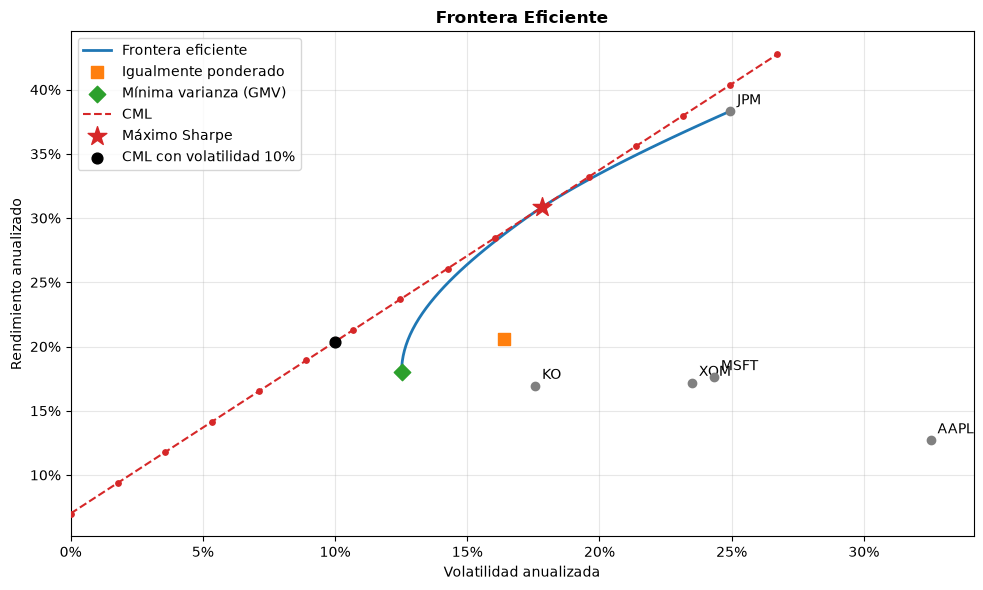

In [25]:
fig, ax = ap.plot_frontera_eficiente(rend_esperado, cov, tasa_libre_de_riesgo=rf)

# agregamos los portafolios de la CML y el portafolio con volatilidad objetivo
ax.scatter(cml["Volatilidad"], cml["Rendimiento"], color="#d62728", s=15, zorder=4)
ax.scatter(vol_objetivo, ap.rendimiento_cml(vol_objetivo, rend_msr, vol_msr, rf),
           color="black", marker="o", s=60, zorder=6, label=f"CML con volatilidad {vol_objetivo:.0%}")
ax.legend(loc="best")

## Un nuevo problema: sensibilidad del MSR

Para obtener el MSR y la CML usamos **rendimientos esperados**, que son muy difíciles de estimar. Un pequeño cambio en ellos puede generar cambios significativos en los pesos del MSR.

### Caso de 2 activos
Repetimos el ejemplo de la clase: mantenemos fija la matriz de covarianzas y cambiamos sólo el rendimiento esperado de MSFT, probando valores alrededor del rendimiento esperado de KO.

In [26]:
activos_2 = ["KO", "MSFT"]
rend_esperado_2 = rend_esperado[activos_2]
cov_2 = cov.loc[activos_2, activos_2]

# rendimientos esperados a probar para MSFT: de 10 puntos por debajo a 10 puntos por encima del de KO
valores = rend_esperado_2["KO"] + np.arange(-0.10, 0.101, 0.02)
pesos_msr_sens, pesos_gmv_sens = ap.sensibilidad_pesos(rend_esperado_2, cov_2, "MSFT", valores, rf)
pesos_msr_sens.round(4)

Ticker,KO,MSFT
Rendimiento esperado de MSFT,,
0.0694,0.9136,0.0864
0.0894,0.8364,0.1636
0.1094,0.7740,0.2260
0.1294,0.7213,0.2787
0.1494,0.6771,0.3229
0.1694,0.6397,0.3603
0.1894,0.6072,0.3928
0.2094,0.5788,0.4212
0.2294,0.5536,0.4464


(<Figure size 1400x500 with 2 Axes>,
 <Axes: title={'center': 'Pesos del GMV'}, xlabel='Rendimiento esperado de MSFT', ylabel='Peso'>)

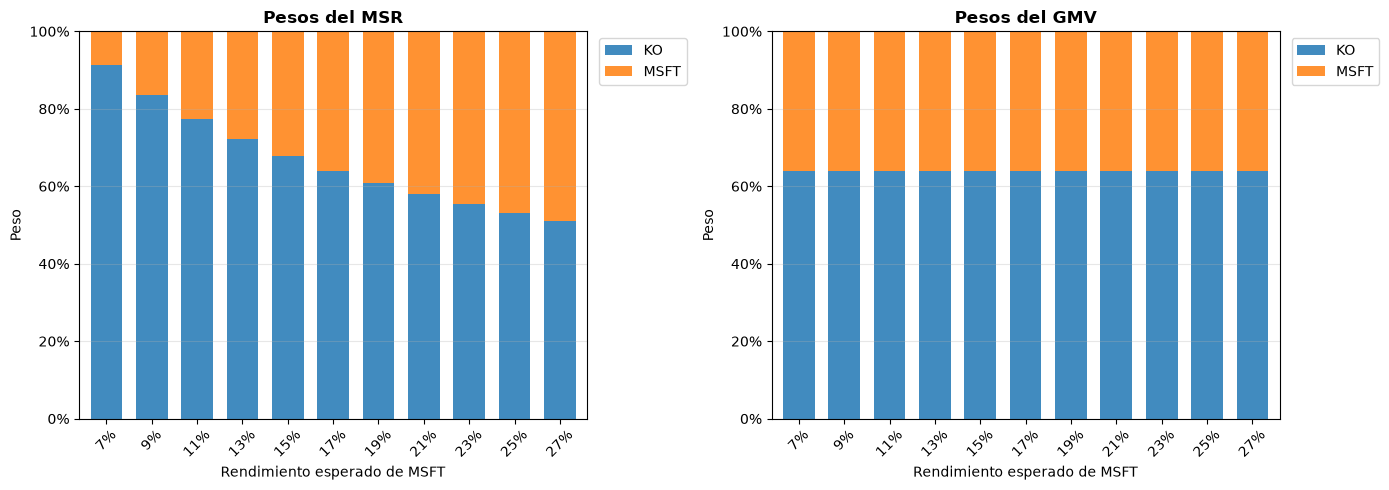

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ap.plot_pesos_apilados(pesos_msr_sens, titulo="Pesos del MSR", ax=axes[0])
ap.plot_pesos_apilados(pesos_gmv_sens, titulo="Pesos del GMV", ax=axes[1])

Los pesos del MSR cambian con cada rendimiento esperado, mientras que los del GMV no se mueven porque **no dependen de los rendimientos esperados**.

**NOTA:** Si el rendimiento esperado de un activo es menor a la tasa libre de riesgo, el MSR le asigna poco o nada de peso.

### Caso de N activos
Ahora simulamos errores de estimación pequeños: a cada rendimiento esperado le sumamos un error aleatorio con desviación estándar de 1 punto porcentual.

In [28]:
generador = np.random.default_rng(42) # semilla para que los resultados sean reproducibles
n_escenarios = 5

escenarios_msr = {"Original": pesos_msr}
for k in range(1, n_escenarios + 1):
    rend_perturbado = rend_esperado + generador.normal(0, 0.01, len(rend_esperado))
    escenarios_msr[f"Escenario {k}"] = ap.portafolio_max_sharpe(rend_perturbado, cov, rf)

escenarios_msr = pd.DataFrame(escenarios_msr, index=rend_esperado.index).T
escenarios_msr.round(4)

Ticker,AAPL,JPM,KO,MSFT,XOM
Original,0.0,0.6497,0.3503,0.0,0.0
Escenario 1,0.0,0.6189,0.3811,0.0,0.0
Escenario 2,0.0,0.6606,0.3394,0.0,0.0
Escenario 3,0.0,0.6549,0.3451,0.0,0.0
Escenario 4,0.0,0.6826,0.3174,0.0,0.0
Escenario 5,0.0,0.6094,0.3906,0.0,0.0


In [29]:
# cambio máximo en el peso de cada activo respecto al MSR original
(escenarios_msr - escenarios_msr.loc["Original"]).abs().max().round(4)

Ticker
AAPL    0.0000
JPM     0.0403
KO      0.0403
MSFT    0.0000
XOM     0.0000
dtype: float64

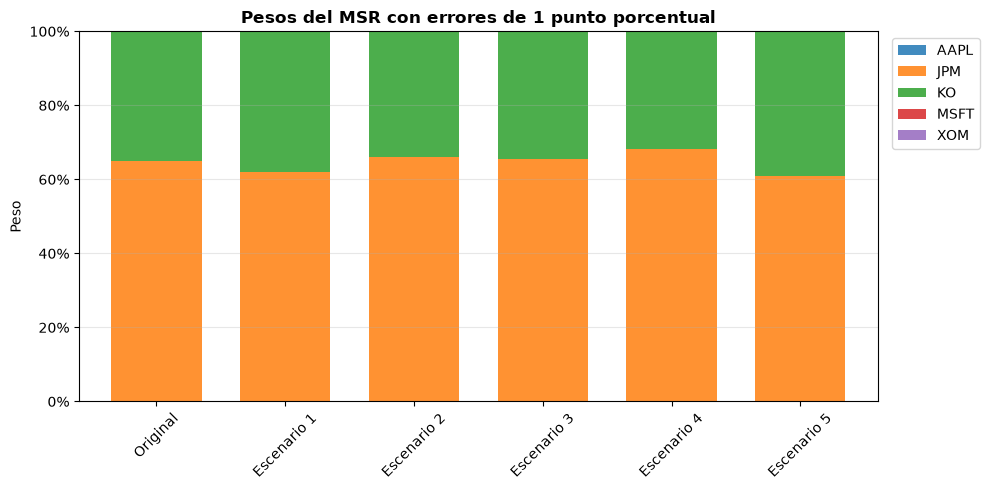

In [30]:
fig, ax = ap.plot_pesos_apilados(escenarios_msr, titulo="Pesos del MSR con errores de 1 punto porcentual")

## Global Minimum Variance Portfolio (GMV)

Una alternativa es el GMV, el portafolio con la menor volatilidad posible. Sus ventajas:

* No necesita rendimientos esperados.
* Sólo es sensible a errores en los parámetros de riesgo (volatilidades y covarianzas), que suelen ser más estables en el tiempo.

In [31]:
pesos_gmv = ap.portafolio_minima_varianza(cov)
pd.Series(pesos_gmv, index=rend_esperado.index).round(4)

Ticker
AAPL    0.0000
JPM     0.0407
KO      0.5238
MSFT    0.2669
XOM     0.1686
dtype: float64

In [32]:
rend_gmv = ap.rendimiento_portafolio(pesos_gmv, rend_esperado)
vol_gmv = ap.volatilidad_portafolio(pesos_gmv, cov)
sharpe_gmv = (rend_gmv - rf) / vol_gmv

print(f"Rendimiento GMV: {rend_gmv:.2%}")
print(f"Volatilidad GMV: {vol_gmv:.2%}")
print(f"Varianza GMV: {vol_gmv**2:.6f}")
print(f"Sharpe GMV: {sharpe_gmv:.4f}")

Rendimiento GMV: 18.03%
Volatilidad GMV: 12.52%
Varianza GMV: 0.015669
Sharpe GMV: 0.8815


### Recordatorio: GMV de 2 activos con fórmula cerrada
Para dos activos el peso del portafolio de mínima varianza es:

$$ w_1 = \frac{\sigma_2^2 - \sigma_{12}}{\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}} \qquad w_2 = 1 - w_1 $$

donde $\sigma_{12} = \rho_{12}\,\sigma_1\sigma_2$. Su volatilidad se obtiene sustituyendo estos pesos en:

$$ \sigma_p = \left( w_1^2\sigma_1^2 + w_2^2\sigma_2^2 + 2 w_1 w_2 \sigma_{12} \right)^{1/2} $$

Observamos que no utiliza rendimientos esperados.

In [33]:
pesos_gmv_formula = ap.pesos_gmv_2_activos(cov_2)
pesos_gmv_optimizador = ap.portafolio_minima_varianza(cov_2)

pd.DataFrame({"Fórmula": pesos_gmv_formula, "Optimizador": pesos_gmv_optimizador}, index=activos_2).round(4)

,Fórmula,Optimizador
KO,0.6394,0.6393
MSFT,0.3606,0.3607


In [34]:
# volatilidad mínima con la fórmula de 2 activos
s1, s2, s12 = cov_2.iloc[0, 0], cov_2.iloc[1, 1], cov_2.iloc[0, 1]
w1, w2 = pesos_gmv_formula
vol_gmv_2 = (w1**2 * s1 + w2**2 * s2 + 2 * w1 * w2 * s12) ** (1 / 2)

print(f"Volatilidad mínima (fórmula): {vol_gmv_2:.2%}")
print(f"Volatilidad mínima (función): {ap.volatilidad_portafolio(pesos_gmv_formula, cov_2):.2%}")

Volatilidad mínima (fórmula): 13.29%
Volatilidad mínima (función): 13.29%


**NOTA:** La fórmula permite ventas en corto, así que puede dar pesos negativos o mayores a 1. En ese caso no coincide con `portafolio_minima_varianza`, que limita los pesos entre 0 y 1.

## Comparación de portafolios

Comparemos tres portafolios: igualmente ponderado (EW), mínima varianza (GMV) y máximo Sharpe (MSR).

Con `rendimientos_historicos_portafolio` construimos la serie diaria de rendimientos de cada portafolio y así podemos reutilizar las funciones de los Labs 1 y 2.

In [35]:
n = len(rend_esperado)
pesos_ew = np.repeat(1 / n, n)

portafolios = {
    "EW": ap.rendimientos_historicos_portafolio(pesos_ew, rend_simple),
    "GMV": ap.rendimientos_historicos_portafolio(pesos_gmv, rend_simple),
    "MSR": ap.rendimientos_historicos_portafolio(pesos_msr, rend_simple),
}
rend_portafolios = pd.DataFrame(portafolios)
rend_portafolios.head()

,EW,GMV,MSR
Date,,,
2025-01-03,0.005345,0.003700,0.008370
2025-01-06,-0.000768,-0.005523,-0.008500
2025-01-07,-0.000939,-0.001186,0.006431
2025-01-08,0.000922,0.006045,0.004902
2025-01-10,-0.012949,-0.010119,-0.012345


In [36]:
comparacion = pd.DataFrame({
    "Rendimiento": ap.rendimiento_anualizado(rend_portafolios),
    "Volatilidad": ap.volatilidad_anualizada(rend_portafolios),
    "Sharpe": ap.sharpe_ratio(rend_portafolios, rf),
    "Max Drawdown": [ap.max_drawdown(rend_portafolios[c])[0] for c in rend_portafolios],
    "VaR 95%": [ap.var_historic(rend_portafolios[c]) for c in rend_portafolios],
    "CVaR 95%": ap.cvar_historic(rend_portafolios),
})
comparacion.round(4)

,Rendimiento,Volatilidad,Sharpe,Max Drawdown,VaR 95%,CVaR 95%
EW,0.2239,0.1638,0.9398,-0.1548,0.0137,0.0223
GMV,0.1962,0.1252,1.0084,-0.0747,0.0093,0.0147
MSR,0.3170,0.1782,1.3859,-0.1611,0.0122,0.0270


**NOTA:** Los portafolios fueron optimizados con los mismos datos con los que los evaluamos (*in-sample*), por eso el MSR luce tan bien. En la práctica los rendimientos esperados son muy difíciles de estimar y el desempeño fuera de muestra suele ser peor.

**NOTA:** Aquí el rendimiento es el geométrico de la serie diaria rebalanceada, por eso difiere un poco de $w^\top r$ calculado arriba.

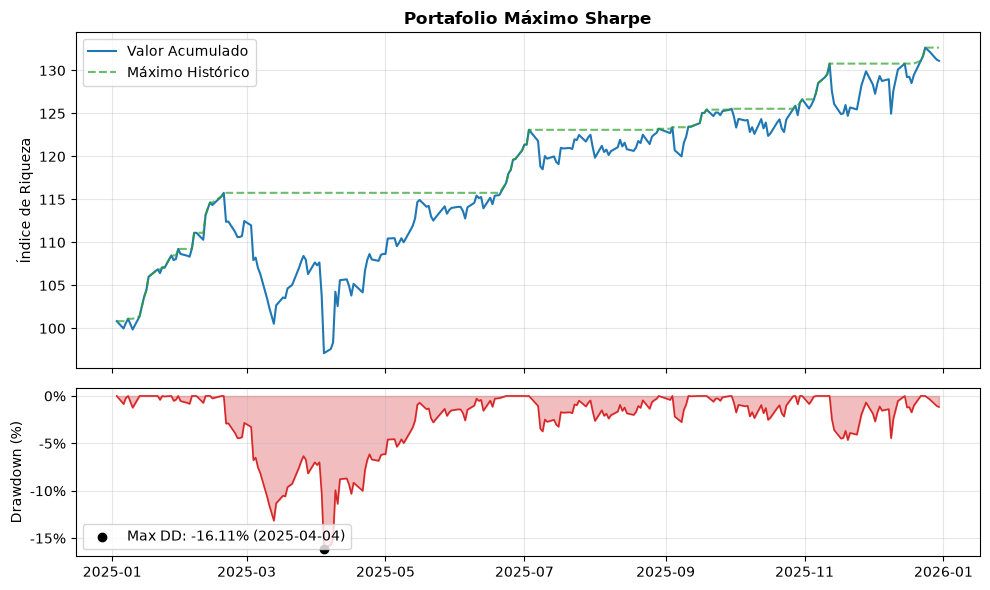

In [37]:
# Visualizamos el drawdown del portafolio de máximo Sharpe
fig, ax = ap.plot_drawdown(rend_portafolios["MSR"], titulo="Portafolio Máximo Sharpe")

## Resumen de resultados

In [38]:
resumen = pd.Series({
    "Tasa libre de riesgo": rf,
    "Rendimiento MSR": rend_msr,
    "Volatilidad MSR": vol_msr,
    "Sharpe MSR (pendiente CML)": sharpe_msr,
    "Rendimiento GMV": rend_gmv,
    "Volatilidad GMV": vol_gmv,
    "Sharpe GMV": sharpe_gmv,
    f"Proporción en MSR para volatilidad {vol_objetivo:.0%}": a_vol,
    f"Rendimiento CML con volatilidad {vol_objetivo:.0%}": ap.rendimiento_cml(vol_objetivo, rend_msr, vol_msr, rf),
    f"Proporción en MSR para rendimiento {rend_objetivo:.0%}": a_rend,
})
resumen.round(4)

Tasa libre de riesgo                      0.0700
Rendimiento MSR                           0.3083
Volatilidad MSR                           0.1782
Sharpe MSR (pendiente CML)                1.3373
Rendimiento GMV                           0.1803
Volatilidad GMV                           0.1252
Sharpe GMV                                0.8815
Proporción en MSR para volatilidad 10%    0.5611
Rendimiento CML con volatilidad 10%       0.2037
Proporción en MSR para rendimiento 25%    0.7553
dtype: float64

In [39]:
pd.DataFrame({"MSR": pesos_msr, "GMV": pesos_gmv, "EW": pesos_ew}, index=rend_esperado.index).round(4)

,MSR,GMV,EW
Ticker,,,
AAPL,0.0000,0.0000,0.2
JPM,0.6497,0.0407,0.2
KO,0.3503,0.5238,0.2
MSFT,0.0000,0.2669,0.2
XOM,0.0000,0.1686,0.2
